# Pipeline Final

Nesse notebook iremos fazer a execução fim-a-fim do Projeto Integrador

1. Extração e Transformação dos Dados
2. Salvar os arquivos processados para uso futuro
3. Transformações para o Modelo de PLN
4. Treino do modelo de PLN
5. Salvar o modelo treinado para uso futuro

## 1. Extração e Transformação

In [1]:
!pip install github-content-downloader

In [2]:
### 1.1 Preparação do Ambiente

import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import nltk
import pandas as pd
import seaborn as sns
import shutil
import tensorflow as tf

from github_downloader import download_from_github
from google.colab import files

from nltk.tokenize import word_tokenize
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neural_network import MLPClassifier
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Baixar pacotes necessários do NLTK
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# Fallback de funções e variáveis caso não estejam carregadas na memória ativa
def remove_stopwords_and_stem(words):
    return [w.lower() for w in words if len(w) > 2]

# Definir diretório de imagens padrão se não definido
images_dir = globals().get('images_dir', '/content/data/raw/images')
os.makedirs(images_dir, exist_ok=True)

# Definir caminhos
raw_data_path = (
    'https://raw.githubusercontent.com/'
    'especializacao-ia-pucsp/'
    'grupo-01-projeto_supervisionado-II/'
    'refs/heads/main/data/raw/chamados.csv'
)
preprocessed_dir = '/content/data/preprocessed'
os.makedirs(preprocessed_dir, exist_ok=True)

### 1.2 Carregar dados brutos
print("Lendo o dataset bruto...")
df_raw = pd.read_csv(raw_data_path)
download_from_github(
    (
        "https://github.com/"
        "especializacao-ia-pucsp/"
        "grupo-01-projeto_supervisionado-II/"
        "tree/main/data/raw/images"
    ),
    dest_folder=images_dir
)

### 1.3 Evitar que as colunas `title` e `description` estejam vazias
df_raw['title'] = df_raw['title'].astype(str).fillna('')
df_raw['description'] = df_raw['description'].astype(str).fillna('')

### 1.4. Pré-processamento e vetorização de texto
print("Pré-processando o texto...")
df_raw['title_words'] = df_raw['title'].apply(word_tokenize)
df_raw['description_words'] = df_raw['description'].apply(word_tokenize)

df_raw['title_stemmed'] = df_raw['title_words'].apply(remove_stopwords_and_stem)
df_raw['description_stemmed'] = df_raw['description_words'].apply(remove_stopwords_and_stem)

df_raw['title_stemmed_str'] = df_raw['title_stemmed'].apply(lambda x: ' '.join(x))
df_raw['description_stemmed_str'] = df_raw['description_stemmed'].apply(lambda x: ' '.join(x))

### 1.5. Encodar os Rótulos
le = LabelEncoder()
le.fit_transform(df_raw['target_category'])

""" Dada a baixa performance da Visão Computacional,
    removemos a etapa de pré-processamento e vetorização de imagens.
    Está comentado porque pode ser alterado no futuro
    (e é bom não perder o código)

### 1.7. Estruturar caminhos e pré-processar as Imagens brutas
print("Processando imagens físicas para a model_vision...")
if 'image_path' in df_raw.columns:
    df_raw['full_image_path'] = df_raw['image_path'].apply(lambda x: os.path.join(images_dir, os.path.basename(str(x))))
else:
    df_raw['full_image_path'] = ''

image_arrays = []
for idx, img_path in enumerate(df_raw['full_image_path']):
    try:
        img = load_img(img_path, target_size=(224, 224))
        img_arr = img_to_array(img)
        img_preprocessed = preprocess_input(img_arr)
        image_arrays.append(img_preprocessed)
    except Exception as e:
        # Fallback de imagem em branco caso haja falha de carregamento ou arquivo ausente
        image_arrays.append(np.zeros((224, 224, 3)))

images_preprocessed = np.array(image_arrays)
"""


Lendo o dataset bruto...
Downloaded: /content/data/raw/images/access_denied.png
Downloaded: /content/data/raw/images/browser.png
Downloaded: /content/data/raw/images/cooler.png
Downloaded: /content/data/raw/images/default_access.png
Downloaded: /content/data/raw/images/default_finance.png
Downloaded: /content/data/raw/images/default_hardware.png
Downloaded: /content/data/raw/images/default_hr.png
Downloaded: /content/data/raw/images/default_network.png
Downloaded: /content/data/raw/images/default_software.png
Downloaded: /content/data/raw/images/email.png
Downloaded: /content/data/raw/images/finance_report.png
Downloaded: /content/data/raw/images/hard_drive.png
Downloaded: /content/data/raw/images/hr_portal.png
Downloaded: /content/data/raw/images/keyboard.png
Downloaded: /content/data/raw/images/login.png
Downloaded: /content/data/raw/images/monitor.png
Downloaded: /content/data/raw/images/motherboard.png
Downloaded: /content/data/raw/images/mouse.png
Downloaded: /content/data/raw/ima

' Dada a baixa performance da Visão Computacional,\n    removemos a etapa de pré-processamento e vetorização de imagens.\n    Está comentado porque pode ser alterado no futuro\n    (e é bom não perder o código)\n\n### 1.7. Estruturar caminhos e pré-processar as Imagens brutas\nprint("Processando imagens físicas para a model_vision...")\nif \'image_path\' in df_raw.columns:\n    df_raw[\'full_image_path\'] = df_raw[\'image_path\'].apply(lambda x: os.path.join(images_dir, os.path.basename(str(x))))\nelse:\n    df_raw[\'full_image_path\'] = \'\'\n\nimage_arrays = []\nfor idx, img_path in enumerate(df_raw[\'full_image_path\']):\n    try:\n        img = load_img(img_path, target_size=(224, 224))\n        img_arr = img_to_array(img)\n        img_preprocessed = preprocess_input(img_arr)\n        image_arrays.append(img_preprocessed)\n    except Exception as e:\n        # Fallback de imagem em branco caso haja falha de carregamento ou arquivo ausente\n        image_arrays.append(np.zeros((224,

## 2. Salvar os Arquivos Pré-processados

In [4]:
### 2.1. Salvar os dados processados para inspeção e uso nos próximos passos
print("Salvando dados estruturados pré-processados...")
df_raw.to_csv(os.path.join(preprocessed_dir, 'df_preprocessed.csv'), index=False)
joblib.dump(le, os.path.join(preprocessed_dir, 'label_encoder.joblib'))

print(f"Sucesso absoluto! Todas as imagens e textos pré-processados salvos em: '{preprocessed_dir}'")



Salvando dados estruturados pré-processados...
Sucesso absoluto! Todas as imagens e textos pré-processados salvos em: '/content/data/preprocessed'


In [5]:
### 2.2. Definição dos caminhos das pastas e arquivos
preprocessed_dir = '/content/data/preprocessed'
model_text_path = 'mlp_emb.joblib'

### 2.3. Carregando os Metadados e o Label Encoder
print("Carregando estruturas de suporte...")
df = pd.read_csv(os.path.join(preprocessed_dir, 'df_preprocessed.csv'))
le = joblib.load(os.path.join(preprocessed_dir, 'label_encoder.joblib'))

""" Não estamos mais gerando as imagens
### 2.4. Carregando os arrays Numpy pré-processados
with np.load(os.path.join(preprocessed_dir, 'images_preprocessed.npz')) as raw_npz:
    images_preprocessed = raw_npz['data']
"""

print(f"✓ Dados carregados: DataFrame {df.shape}") # | Imagens {images_preprocessed.shape}")


Carregando estruturas de suporte...
✓ Dados carregados: DataFrame (5000, 50)


## 3. Transformações para o Modelo de PLN



In [11]:
### 3.1. Preparar dados para a Camada de Embedding
# Criando e ajustando os vectorizers para extrair o vocabulário das colunas textuais
title_count_vectorizer = CountVectorizer()
title_count_vectorizer.fit(df['title_stemmed_str'].fillna(''))

description_count_vectorizer = CountVectorizer()
description_count_vectorizer.fit(df['description_stemmed_str'].fillna(''))

title_word_index = {word: idx + 1 for idx, word in enumerate(title_count_vectorizer.get_feature_names_out())}
description_word_index = {word: idx + 1 for idx, word in enumerate(description_count_vectorizer.get_feature_names_out())}

### 3.2. Converter texto para sequências de inteiros
title_sequences = [[title_word_index.get(word, 0) for word in str(text).split()] for text in df['title_stemmed_str']]
description_sequences = [[description_word_index.get(word, 0) for word in str(text).split()] for text in df['description_stemmed_str']]

### 3.3. Determinar comprimento máximo para padding
max_title_len = max(len(seq) for seq in title_sequences) if title_sequences else 1
max_description_len = max(len(seq) for seq in description_sequences) if description_sequences else 1

### 3.4. Aplicar padding às sequências
padded_title_sequences = pad_sequences(title_sequences, maxlen=max_title_len, padding='post', truncating='post')
padded_description_sequences = pad_sequences(description_sequences, maxlen=max_description_len, padding='post', truncating='post')

### 3.5. Definir um modelo simples com uma Camada de Embedding
vocab_size_title = len(title_word_index) + 1 # +1 para o índice 0 (padding/palavras desconhecidas)
vocab_size_description = len(description_word_index) + 1
embedding_dim = 100 # Dimensão dos vetores de embedding

### 3.6. Modelo de Embedding para títulos
title_embedding_model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=vocab_size_title, output_dim=embedding_dim, input_length=max_title_len),
    tf.keras.layers.GlobalAveragePooling1D() # Para obter um embedding de documento de tamanho fixo
])

### 3.7. Modelo de Embedding para descrições
description_embedding_model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=vocab_size_description, output_dim=embedding_dim, input_length=max_description_len),
    tf.keras.layers.GlobalAveragePooling1D() # Para obter um embedding de documento de tamanho fixo
])

### 3.8. Gerar Embeddings
print("\nGerando embeddings para títulos...")
title_embeddings = title_embedding_model.predict(padded_title_sequences)
print(f"Shape dos embeddings de títulos: {title_embeddings.shape}")

print("Gerando embeddings para descrições...")
description_embeddings = description_embedding_model.predict(padded_description_sequences)
print(f"Shape dos embeddings de descrições: {description_embeddings.shape}")

### 3.9. Monta os DataFrames de embeddings já com o ticket_id como identificador
df_title_embeddings = pd.DataFrame(
    title_embeddings,
    columns=[f'title_emb_{i}' for i in range(title_embeddings.shape[1])]
)
df_title_embeddings.insert(0, 'ticket_id', df['ticket_id'].values)

df_description_embeddings = pd.DataFrame(
    description_embeddings,
    columns=[f'desc_emb_{i}' for i in range(description_embeddings.shape[1])]
)
df_description_embeddings.insert(0, 'ticket_id', df['ticket_id'].values)

### 3.10. Aplicar PCA
def aplicar_pca(embeddings, nome, variancia_desejada=0.80):
    # PCA com número de componentes que preserva a variância desejada
    pca = PCA(n_components=variancia_desejada, svd_solver='full', random_state=42)
    embeddings_reduzidos = pca.fit_transform(embeddings)

    print(f"[{nome}] Dimensão original: {embeddings.shape[1]}")
    print(f"[{nome}] Dimensão após PCA ({variancia_desejada*100:.0f}% da variância): {embeddings_reduzidos.shape[1]}")

    return pca, embeddings_reduzidos

pca_title, title_embeddings_pca = aplicar_pca(title_embeddings, 'Título')
pca_description, description_embeddings_pca = aplicar_pca(description_embeddings, 'Descrição')

df_title_embeddings_pca = pd.DataFrame(
    title_embeddings_pca,
    columns=[f'title_pca_{i}' for i in range(title_embeddings_pca.shape[1])]
)
df_title_embeddings_pca.insert(0, 'ticket_id', df['ticket_id'].values)

df_description_embeddings_pca = pd.DataFrame(
    description_embeddings_pca,
    columns=[f'desc_pca_{i}' for i in range(description_embeddings_pca.shape[1])]
)
df_description_embeddings_pca.insert(0, 'ticket_id', df['ticket_id'].values)

### 3.11. Junta as versões reduzidas por PCA de volta ao df principal, usando ticket_id
df = df.merge(df_title_embeddings_pca, on='ticket_id', how='left')
df = df.merge(df_description_embeddings_pca, on='ticket_id', how='left')

print(f"Shape de df após o merge: {df.shape}")
display(df.head())

assert df.shape[0] == 5000, f"Esperado 5000 linhas, veio {df.shape[0]}"
assert df.filter(like='title_pca_').isnull().sum().sum() == 0, "Há tickets sem embedding de título"
assert df.filter(like='desc_pca_').isnull().sum().sum() == 0, "Há tickets sem embedding de descrição"
print("OK — merge íntegro, sem duplicatas ou nulos.")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(



Gerando embeddings para títulos...
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Shape dos embeddings de títulos: (5000, 100)
Gerando embeddings para descrições...
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Shape dos embeddings de descrições: (5000, 100)
[Título] Dimensão original: 100
[Título] Dimensão após PCA (80% da variância): 23
[Descrição] Dimensão original: 100
[Descrição] Dimensão após PCA (80% da variância): 21
Shape de df após o merge: (5000, 137)


,ticket_id,created_at,customer_id,department,city_x,state_x,device_type,os,browser,network_type,...,desc_pca_11_y,desc_pca_12_y,desc_pca_13_y,desc_pca_14_y,desc_pca_15_y,desc_pca_16_y,desc_pca_17_y,desc_pca_18_y,desc_pca_19_y,desc_pca_20_y
0,1,2025-01-01T00:17:00,5012,Operações,Campinas,BA,Desktop,Windows,Safari,WiFi,...,-0.017455,0.019954,0.011975,0.019344,0.000699,-0.003619,0.007317,0.000947,-0.016339,0.004243
1,2,2025-01-01T00:34:00,6574,Financeiro,Campinas,RJ,Notebook,Windows,Chrome,5G,...,0.011990,-0.020571,-0.012211,0.008403,-0.008181,-0.002914,0.001866,0.001525,0.010521,0.009431
2,3,2025-01-01T00:51:00,2139,TI,Campinas,MG,Desktop,Linux,Chrome,5G,...,0.025225,-0.017208,-0.019234,-0.018964,0.003394,-0.002615,0.008499,-0.017005,0.003322,0.004716
3,4,2025-01-01T01:08:00,7216,Financeiro,Belo Horizonte,RJ,Mobile,Android,Chrome,Cabo,...,-0.009732,0.010189,-0.020595,-0.000842,0.016822,-0.006444,0.000966,-0.002176,-0.002022,-0.011093
4,5,2025-01-01T01:25:00,5040,Financeiro,Belo Horizonte,PR,Mobile,iOS,Edge,Cabo,...,0.003034,0.002975,0.019848,-0.006433,-0.006936,-0.002519,0.009995,-0.002975,0.004904,-0.000023


OK — merge íntegro, sem duplicatas ou nulos.


In [12]:
# 3.12. Salvar os dados já processados
processed_dir = '/content/data/processed'
os.makedirs(processed_dir, exist_ok=True)

output_csv_path = os.path.join(processed_dir, 'chamados.csv')
df.to_csv(output_csv_path, index=False)

print(f"DataFrame salvo com sucesso em: '{output_csv_path}'")

DataFrame salvo com sucesso em: '/content/data/processed/chamados.csv'


## 4. Treino do modelo de PLN

In [16]:

### 4.1. Carregando os dados processados
processed_csv_path = '/content/data/processed/chamados.csv'
if os.path.exists(processed_csv_path):
    df = pd.read_csv(processed_csv_path)
    print(f"DataFrame carregado com sucesso de '{processed_csv_path}'! Formato: {df.shape}")
    display(df.head())
else:
    print(f"Erro: O arquivo '{processed_csv_path}' não foi encontrado.")

### 4.2. Separando os dados em treino, validação e testes
# Recriando a variável de target (y) a partir do LabelEncoder e DataFrame carregados
y = le.transform(df['target_category'])
X_index = df.index.values

idx_treino_val, idx_teste = train_test_split(
    X_index, test_size=0.10, random_state=42, stratify=y
)
idx_treino, idx_val = train_test_split(
    idx_treino_val, test_size=0.111, random_state=42, stratify=y[idx_treino_val]
)  # 0.111 de 90% ≈ 10% do total

print(f"Treino: {len(idx_treino)} | Validação: {len(idx_val)} | Teste: {len(idx_teste)}")

DataFrame carregado com sucesso de '/content/data/processed/chamados.csv'! Formato: (5000, 137)


/tmp/ipykernel_3351/2859031387.py:4: DtypeWarning: Columns (27,28,30,31,32,33,34) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(processed_csv_path)


,ticket_id,created_at,customer_id,department,city_x,state_x,device_type,os,browser,network_type,...,desc_pca_11_y,desc_pca_12_y,desc_pca_13_y,desc_pca_14_y,desc_pca_15_y,desc_pca_16_y,desc_pca_17_y,desc_pca_18_y,desc_pca_19_y,desc_pca_20_y
0,1,2025-01-01T00:17:00,5012,Operações,Campinas,BA,Desktop,Windows,Safari,WiFi,...,-0.017455,0.019954,0.011975,0.019344,0.000699,-0.003619,0.007317,0.000947,-0.016339,0.004243
1,2,2025-01-01T00:34:00,6574,Financeiro,Campinas,RJ,Notebook,Windows,Chrome,5G,...,0.011990,-0.020571,-0.012211,0.008403,-0.008181,-0.002914,0.001866,0.001525,0.010521,0.009431
2,3,2025-01-01T00:51:00,2139,TI,Campinas,MG,Desktop,Linux,Chrome,5G,...,0.025225,-0.017208,-0.019234,-0.018964,0.003394,-0.002615,0.008499,-0.017005,0.003322,0.004716
3,4,2025-01-01T01:08:00,7216,Financeiro,Belo Horizonte,RJ,Mobile,Android,Chrome,Cabo,...,-0.009732,0.010189,-0.020595,-0.000842,0.016822,-0.006444,0.000966,-0.002176,-0.002022,-0.011093
4,5,2025-01-01T01:25:00,5040,Financeiro,Belo Horizonte,PR,Mobile,iOS,Edge,Cabo,...,0.003034,0.002975,0.019848,-0.006433,-0.006936,-0.002519,0.009995,-0.002975,0.004904,-0.000023


Treino: 4000 | Validação: 500 | Teste: 500


In [17]:


### 4.3. Colunas de embeddings (PCA) já mergeadas no df
colunas_pca = [c for c in df.columns if c.startswith('title_pca_') or c.startswith('desc_pca_')]
print(f"{len(colunas_pca)} colunas de embeddings PCA")

X_emb_treino = df.loc[idx_treino, colunas_pca].values
X_emb_val    = df.loc[idx_val, colunas_pca].values
X_emb_teste  = df.loc[idx_teste, colunas_pca].values

scaler_emb = StandardScaler()
X_emb_treino_scaled = scaler_emb.fit_transform(X_emb_treino)
X_emb_val_scaled    = scaler_emb.transform(X_emb_val)
X_emb_teste_scaled  = scaler_emb.transform(X_emb_teste)

y_treino = y[idx_treino]
y_val    = y[idx_val]
y_teste  = y[idx_teste]

mlp_emb = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size=200,
    max_iter=50,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=42,
    verbose=True
)
mlp_emb.fit(X_emb_treino_scaled, y_treino)

y_pred_emb = mlp_emb.predict(X_emb_teste_scaled)
print(f"\nAcurácia (só embeddings PCA): {accuracy_score(y_teste, y_pred_emb):.4f}")
print(classification_report(y_teste, y_pred_emb, target_names=le.classes_))

87 colunas de embeddings PCA
Iteration 1, loss = 1.47583333
Validation score: 0.725000
Iteration 2, loss = 0.67381460
Validation score: 0.870000
Iteration 3, loss = 0.33510482
Validation score: 0.932500
Iteration 4, loss = 0.19983771
Validation score: 0.932500
Iteration 5, loss = 0.13932868
Validation score: 0.945000
Iteration 6, loss = 0.10656043
Validation score: 0.940000
Iteration 7, loss = 0.08583878
Validation score: 0.942500
Iteration 8, loss = 0.07322281
Validation score: 0.952500
Iteration 9, loss = 0.06688202
Validation score: 0.955000
Iteration 10, loss = 0.05977718
Validation score: 0.947500
Iteration 11, loss = 0.05499167
Validation score: 0.952500
Iteration 12, loss = 0.05121302
Validation score: 0.950000
Iteration 13, loss = 0.04972650
Validation score: 0.955000
Iteration 14, loss = 0.04705482
Validation score: 0.957500
Iteration 15, loss = 0.04603156
Validation score: 0.962500
Iteration 16, loss = 0.04461944
Validation score: 0.952500
Iteration 17, loss = 0.04236415
Vali

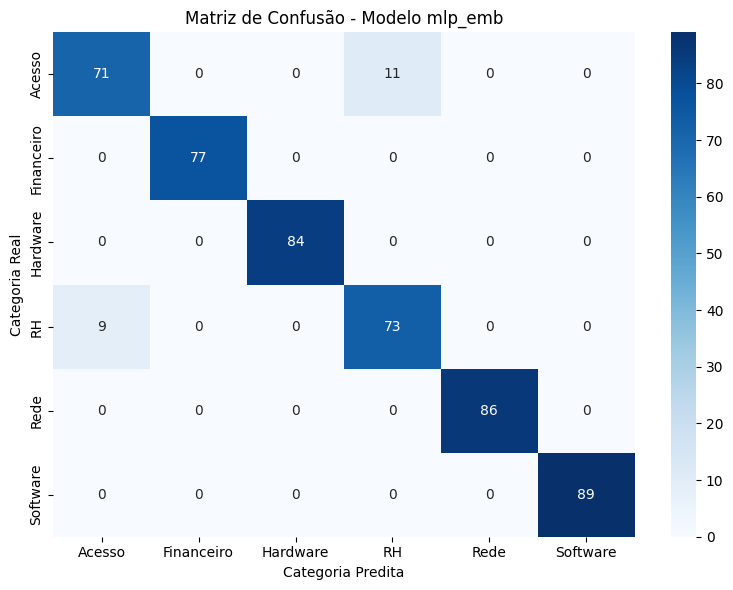

In [18]:
### 4.4. Calcular a matriz de confusão utilizando os rótulos reais e preditos do conjunto de teste
cm = confusion_matrix(y_teste, y_pred_emb)

### 4.5. Plotar a matriz usando seaborn para melhor legibilidade
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)
plt.title('Matriz de Confusão - Modelo mlp_emb')
plt.ylabel('Categoria Real')
plt.xlabel('Categoria Predita')
plt.tight_layout()
plt.show()

## 5. Salvar o modelo treinado para uso futuro

In [19]:
### 5.1. Definir caminhos e criar o diretório de modelos se não existir
models_dir = '/content/data/models'
os.makedirs(models_dir, exist_ok=True)

### 5.2. Salvar o modelo mlp_emb treinado
model_save_path = os.path.join(models_dir, 'mlp_emb.joblib')
joblib.dump(mlp_emb, model_save_path)
print(f"✓ Modelo treinado salvo com sucesso em: '{model_save_path}'")

### 5.3. Criar uma pasta temporária para organizar o ZIP
zip_source_dir = '/content/temp_zip_dir'
os.makedirs(zip_source_dir, exist_ok=True)

### 5.4. Copiar as pastas models e processed para dentro da pasta temporária
if os.path.exists(models_dir):
    shutil.copytree(models_dir, os.path.join(zip_source_dir, 'models'), dirs_exist_ok=True)
if os.path.exists('/content/data/processed'):
    shutil.copytree('/content/data/processed', os.path.join(zip_source_dir, 'processed'), dirs_exist_ok=True)

### 5.5. Criar o arquivo ZIP
zip_output_path = '/content/processed_and_models'
shutil.make_archive(zip_output_path, 'zip', zip_source_dir)
print(f"✓ Arquivo ZIP criado com sucesso em: '{zip_output_path}.zip'")

### 5.6. Oferecer download do arquivo
files.download(f"{zip_output_path}.zip")

✓ Modelo treinado salvo com sucesso em: '/content/data/models/mlp_emb.joblib'
✓ Arquivo ZIP criado com sucesso em: '/content/processed_and_models.zip'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>